# CodeNova Internship — Task 1: Exploratory Data Analysis (EDA)

**Dataset:** Palmer Penguins  
**Goal:** Profile and clean a public dataset, create required visualizations, and document evidence-based observations.

## How to use
1. Open this folder in VS Code.
2. Install the packages from `requirements.txt`.
3. Select your Python kernel in the notebook.
4. Run **Run All** from top to bottom.
5. Review the outputs and update the findings in the final section using your actual results.

The notebook downloads the CSV from the public Seaborn data repository if `penguins.csv` is not already present in this folder. An internet connection is needed for that first download.

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "penguins.csv"
OUTPUT_DIR = PROJECT_DIR / "visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)

DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

if not DATA_PATH.exists():
    print("Downloading the Palmer Penguins dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Setup complete.")
print("Project folder:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)

Setup complete.
Project folder: c:\Users\DELL\OneDrive\Desktop\CodeNova_Task_1_EDA
Dataset path: c:\Users\DELL\OneDrive\Desktop\CodeNova_Task_1_EDA\penguins.csv


## 1. Load and inspect the dataset

We start by checking the dataset dimensions, column names, data types, summary statistics, and missing values.

In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

missing_before = df.isna().sum()
print("\nMissing values per column:")
display(missing_before.to_frame("Missing values"))
print("Hello! CodeNova Task 1 is working.")

Dataset shape (rows, columns): (344, 7)

Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Data types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB

Sta

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,MALE,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values per column:


,Missing values
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


Hello! CodeNova Task 1 is working.


## 2. Check and remove exact duplicate rows

Exact duplicate rows can unintentionally count the same record more than once. We report the count and remove exact duplicates only.

In [3]:
duplicate_count = int(df.duplicated().sum())
df_clean = df.drop_duplicates().copy()

print("Duplicate rows found:", duplicate_count)
print("Rows before removal:", len(df))
print("Rows after removal:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Duplicate rows found: 0
Rows before removal: 344
Rows after removal: 344
Rows removed: 0


## 3. Handle missing values

Numerical missing values are filled with each column's median; categorical missing values are filled with the most frequent category (mode). This preserves rows, but imputation can affect distributions, so we document it as a limitation.

In [4]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(include=["object", "category", "string"]).columns.tolist()

imputation_log = []

for col in numeric_cols:
    missing_count = int(df_clean[col].isna().sum())
    if missing_count:
        median_value = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_value)
        imputation_log.append({
            "Column": col, "Type": "numeric", "Missing filled": missing_count,
            "Method": "median", "Fill value": median_value
        })

for col in categorical_cols:
    missing_count = int(df_clean[col].isna().sum())
    if missing_count:
        modes = df_clean[col].mode(dropna=True)
        if not modes.empty:
            mode_value = modes.iloc[0]
            df_clean[col] = df_clean[col].fillna(mode_value)
            imputation_log.append({
                "Column": col, "Type": "categorical", "Missing filled": missing_count,
                "Method": "mode", "Fill value": mode_value
            })

print("Missing values before cleaning:")
display(missing_before[missing_before > 0].to_frame("Missing before"))

print("\nImputation log:")
display(pd.DataFrame(imputation_log) if imputation_log else pd.DataFrame(
    columns=["Column", "Type", "Missing filled", "Method", "Fill value"]
))

print("\nMissing values after cleaning:")
display(df_clean.isna().sum().to_frame("Missing after"))

assert df_clean.isna().sum().sum() == 0, "Some missing values remain; inspect the output."

Missing values before cleaning:


,Missing before
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11



Imputation log:


,Column,Type,Missing filled,Method,Fill value
0,bill_length_mm,numeric,2,median,44.45
1,bill_depth_mm,numeric,2,median,17.3
2,flipper_length_mm,numeric,2,median,197.0
3,body_mass_g,numeric,2,median,4050.0
4,sex,categorical,11,mode,MALE



Missing values after cleaning:


,Missing after
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


## 4. Detect potential outliers with the IQR method

For each numerical feature, calculate Q1, Q3, and IQR. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers. These are **not automatically deleted**, because unusual measurements may be genuine.

In [5]:
outlier_results = []

for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df_clean[col] < lower) | (df_clean[col] > upper)

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower,
        "Upper bound": upper,
        "Potential outliers": int(mask.sum())
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df.round(2))
outlier_df.to_csv(OUTPUT_DIR / "outlier_summary.csv", index=False)

,Feature,Q1,Q3,IQR,Lower bound,Upper bound,Potential outliers
0,bill_length_mm,39.28,48.5,9.23,25.44,62.34,0
1,bill_depth_mm,15.60,18.7,3.10,10.95,23.35,0
2,flipper_length_mm,190.00,213.0,23.00,155.50,247.50,0
3,body_mass_g,3550.00,4750.0,1200.00,1750.00,6550.00,0


## 5. Visualize numerical feature distributions

Histograms show the frequency and shape of each numerical feature. Each plot is saved as a high-resolution PNG.

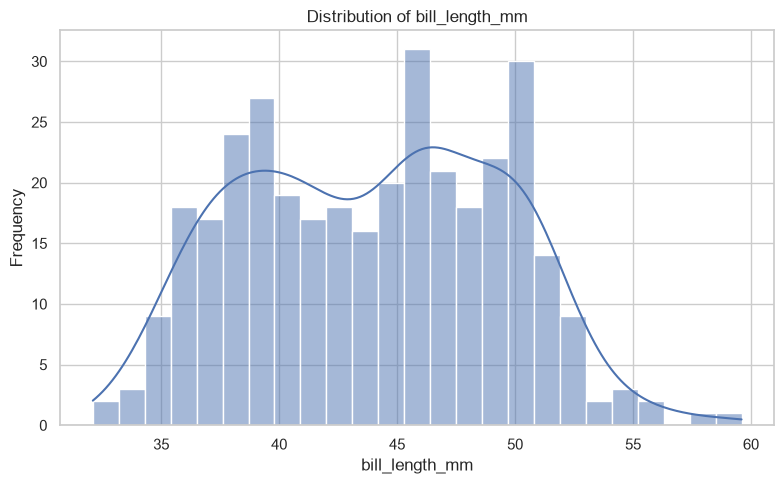

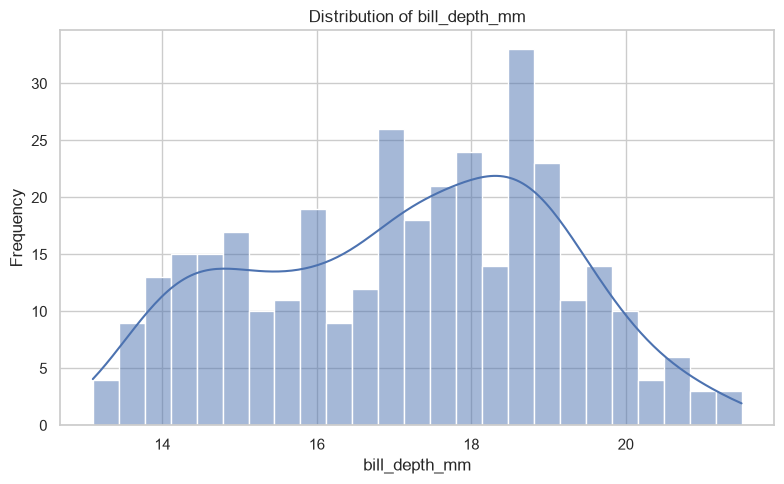

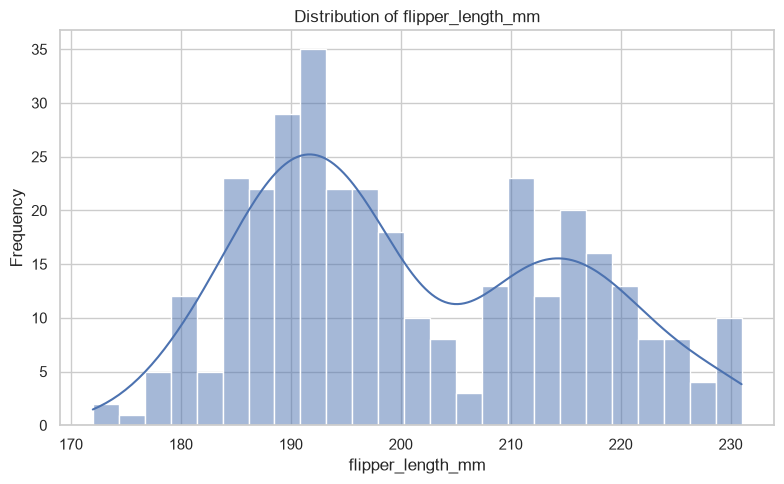

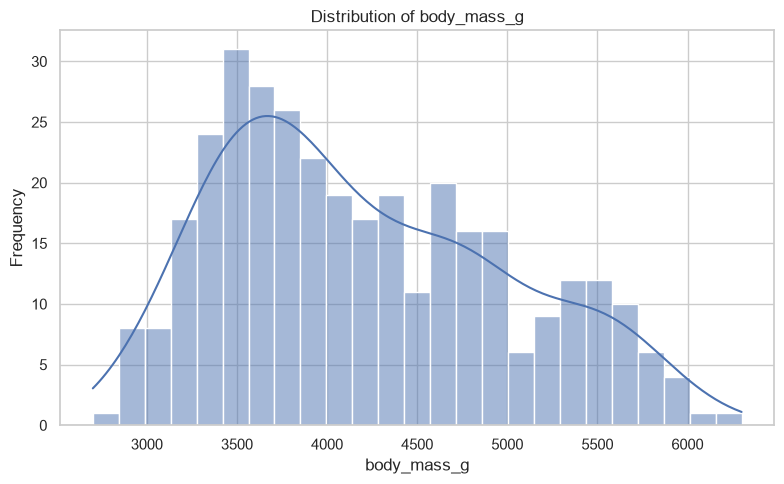

In [6]:
for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(data=df_clean, x=col, kde=True, bins=25, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"distribution_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 6. Boxplots

Boxplots show the median, quartiles, and potential outliers. Compare them with the IQR summary above.

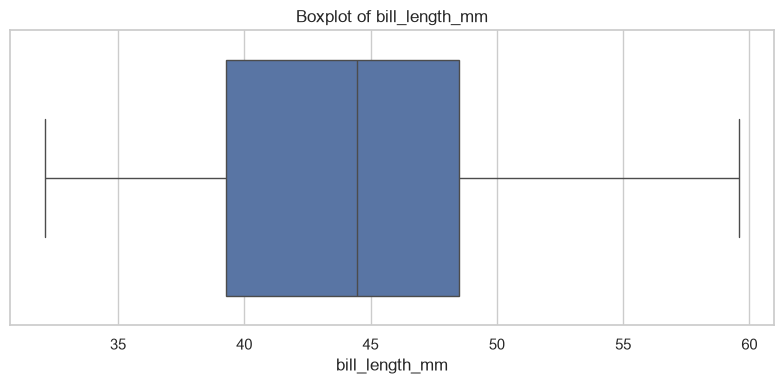

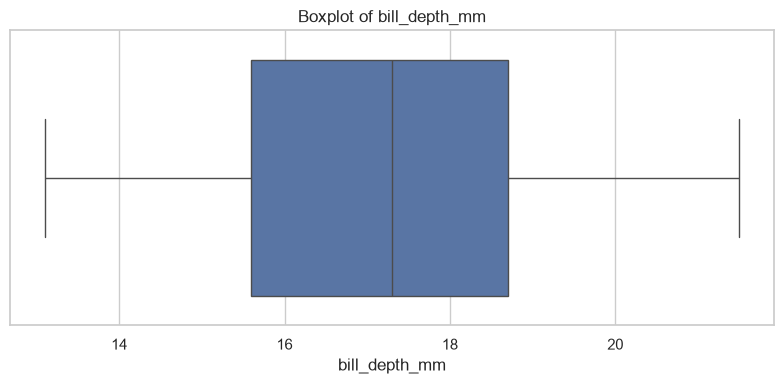

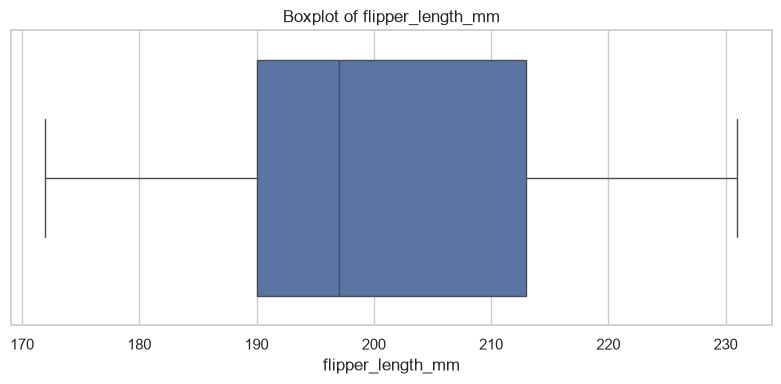

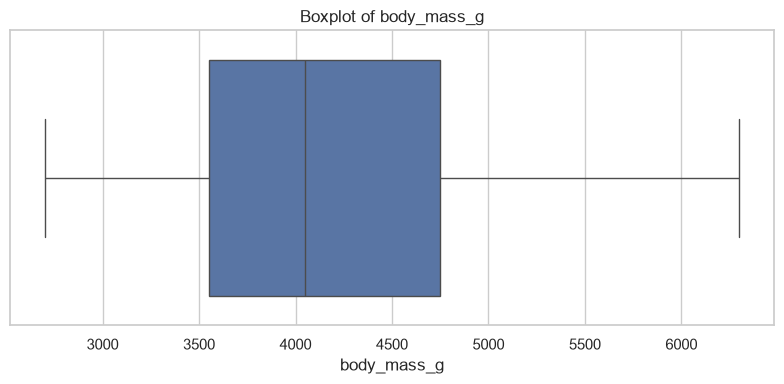

In [7]:
for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=df_clean, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"boxplot_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 7. Correlation heatmap

The heatmap shows linear correlation between numerical variables. Correlation does not establish causation.

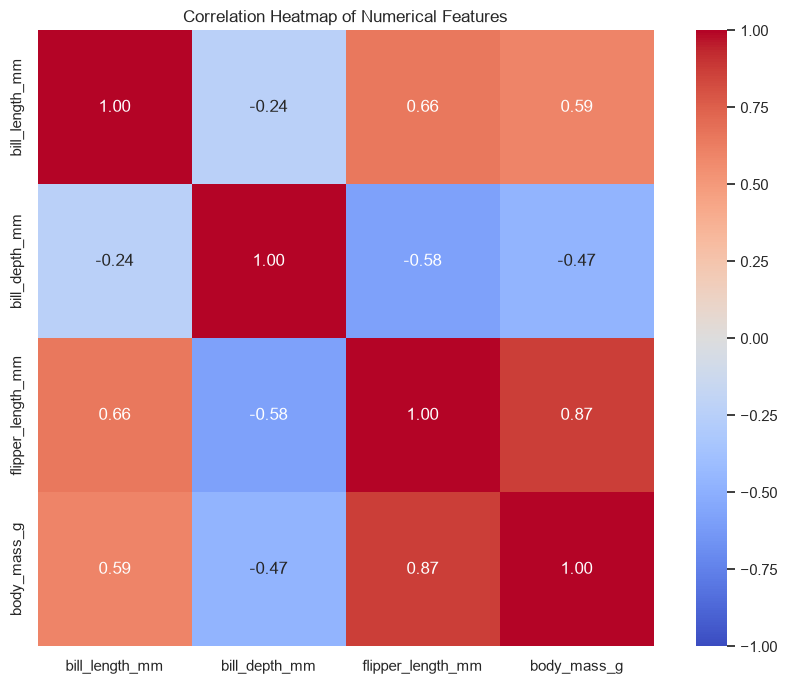

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.59
bill_depth_mm,-0.24,1.00,-0.58,-0.47
flipper_length_mm,0.66,-0.58,1.00,0.87
body_mass_g,0.59,-0.47,0.87,1.00


In [8]:
correlation = df_clean[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    correlation, annot=True, cmap="coolwarm", fmt=".2f",
    vmin=-1, vmax=1, square=True, ax=ax
)
ax.set_title("Correlation Heatmap of Numerical Features")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

display(correlation.round(2))

## 8. Pairwise scatter plots

This plot compares numerical features and colors points by penguin species to help identify group patterns.

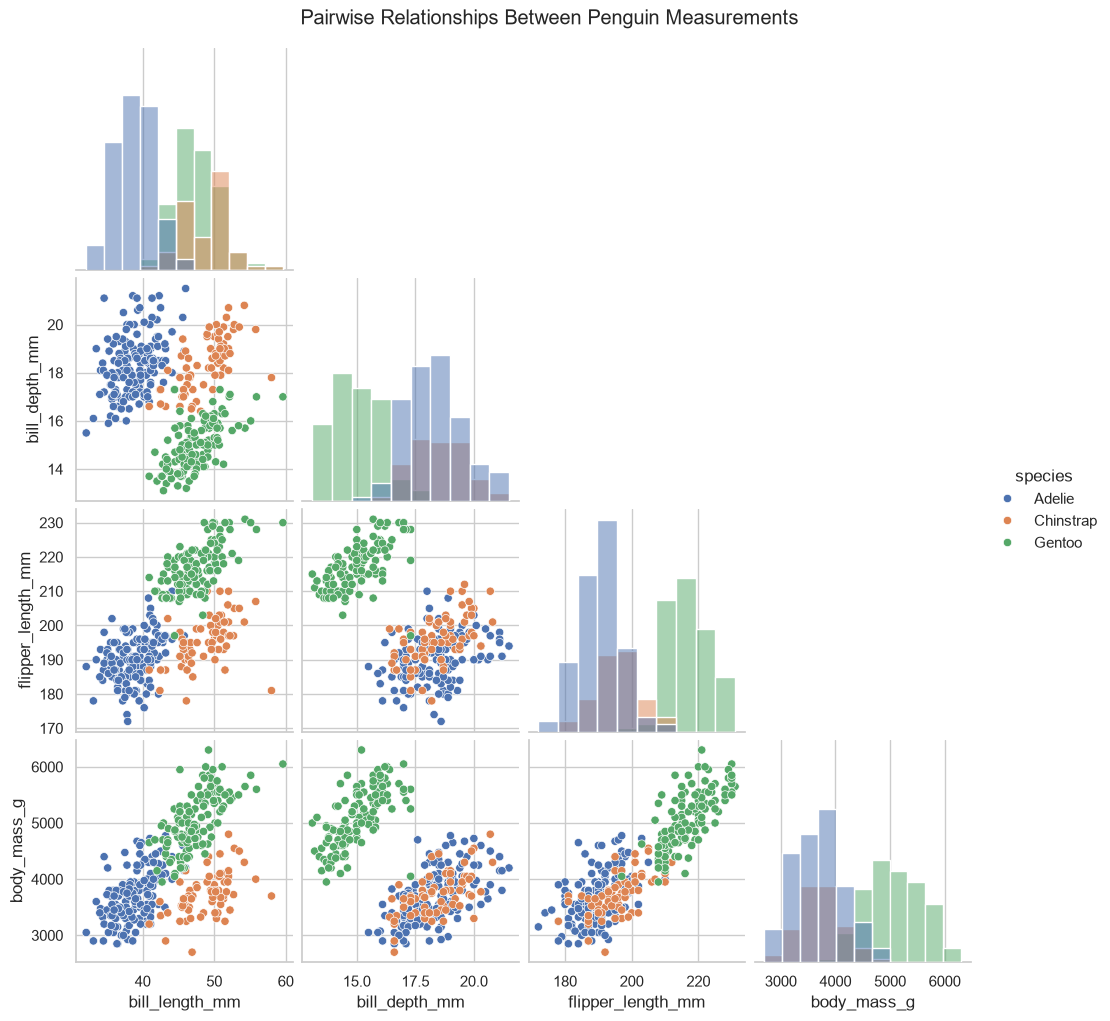

In [9]:
pairplot = sns.pairplot(
    df_clean,
    vars=numeric_cols,
    hue="species",
    diag_kind="hist",
    corner=True
)
pairplot.fig.suptitle("Pairwise Relationships Between Penguin Measurements", y=1.02)
pairplot.savefig(OUTPUT_DIR / "pairwise_scatterplots.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## 9. Summaries to support findings

Use the actual tables and charts above to write findings. Do not claim a pattern unless it is supported by the output.

In [10]:
print("Species counts:")
display(df_clean["species"].value_counts().rename_axis("species").to_frame("count"))

print("\nMean numerical measurements by species:")
display(df_clean.groupby("species")[numeric_cols].mean().round(2))

print("\nMedian numerical measurements by species:")
display(df_clean.groupby("species")[numeric_cols].median().round(2))

print("\nCorrelation matrix:")
display(correlation.round(2))

Species counts:


,count
species,
Adelie,152
Gentoo,124
Chinstrap,68



Mean numerical measurements by species:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.83,18.34,190.00,3702.96
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.48,15.00,217.02,5067.74



Median numerical measurements by species:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.80,18.40,190.0,3700.0
Chinstrap,49.55,18.45,196.0,3700.0
Gentoo,47.25,15.00,216.0,5000.0



Correlation matrix:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.59
bill_depth_mm,-0.24,1.00,-0.58,-0.47
flipper_length_mm,0.66,-0.58,1.00,0.87
body_mass_g,0.59,-0.47,0.87,1.00


## 10. Findings and limitations — complete after reviewing outputs

Replace the prompts below with specific values and observations from the notebook outputs.

1. **Dataset profile:** The dataset contains ___ rows and ___ columns before cleaning.
2. **Data quality:** The original dataset contained ___ missing values and ___ exact duplicate rows.
3. **Distributions:** Describe the distribution of at least two numerical features using the histograms.
4. **Potential outliers:** Identify features with IQR-flagged values. Explain why flags do not automatically mean errors.
5. **Correlations:** Report the strongest relationship shown by the heatmap and its direction.
6. **Species comparison:** Use the grouped summary and pairplot to describe a measurable difference between species.

### Limitations
- Median and mode imputation can alter the original distributions.
- IQR flags identify potential outliers, not necessarily incorrect measurements.
- Correlation does not imply causation.
- The results describe this dataset and may not generalize to all penguins.

## 11. Export cleaned data and verify deliverables

In [11]:
clean_path = PROJECT_DIR / "penguins_cleaned.csv"
df_clean.to_csv(clean_path, index=False)

chart_files = sorted(p.name for p in OUTPUT_DIR.glob("*.png"))
print("Final cleaned shape:", df_clean.shape)
print("Remaining missing values:", int(df_clean.isna().sum().sum()))
print("Remaining duplicate rows:", int(df_clean.duplicated().sum()))
print("\nSaved visualization files:")
for filename in chart_files:
    print("-", filename)

print("\nCleaned dataset saved to:", clean_path)
print("Total PNG charts:", len(chart_files))

assert df_clean.isna().sum().sum() == 0
assert len(chart_files) >= 3, "Check that visualization cells ran successfully."
print("\nEDA pipeline completed. Review the findings section before submission.")

Final cleaned shape: (344, 7)
Remaining missing values: 0
Remaining duplicate rows: 0

Saved visualization files:
- boxplot_bill_depth_mm.png
- boxplot_bill_length_mm.png
- boxplot_body_mass_g.png
- boxplot_flipper_length_mm.png
- correlation_heatmap.png
- distribution_bill_depth_mm.png
- distribution_bill_length_mm.png
- distribution_body_mass_g.png
- distribution_flipper_length_mm.png
- pairwise_scatterplots.png

Cleaned dataset saved to: c:\Users\DELL\OneDrive\Desktop\CodeNova_Task_1_EDA\penguins_cleaned.csv
Total PNG charts: 10

EDA pipeline completed. Review the findings section before submission.
